# Real global NASA extraction, exploration and label quality
This notebook reviews completed scientific subsetting for 24 globally distributed panels and a separate Lebanese dataset. It does **not** represent exhaustive worldwide coverage. Raw selected NASA mask/QA/land-cover/terrain values are retained with source and subset hashes. Model logic lives in Python modules. Conflict boundaries are CDR/OCHA historical review data explicitly requested by the user; environmental predictors remain NASA-only.

Panels: 24 fixed sample dates: 192
Source sites: 18


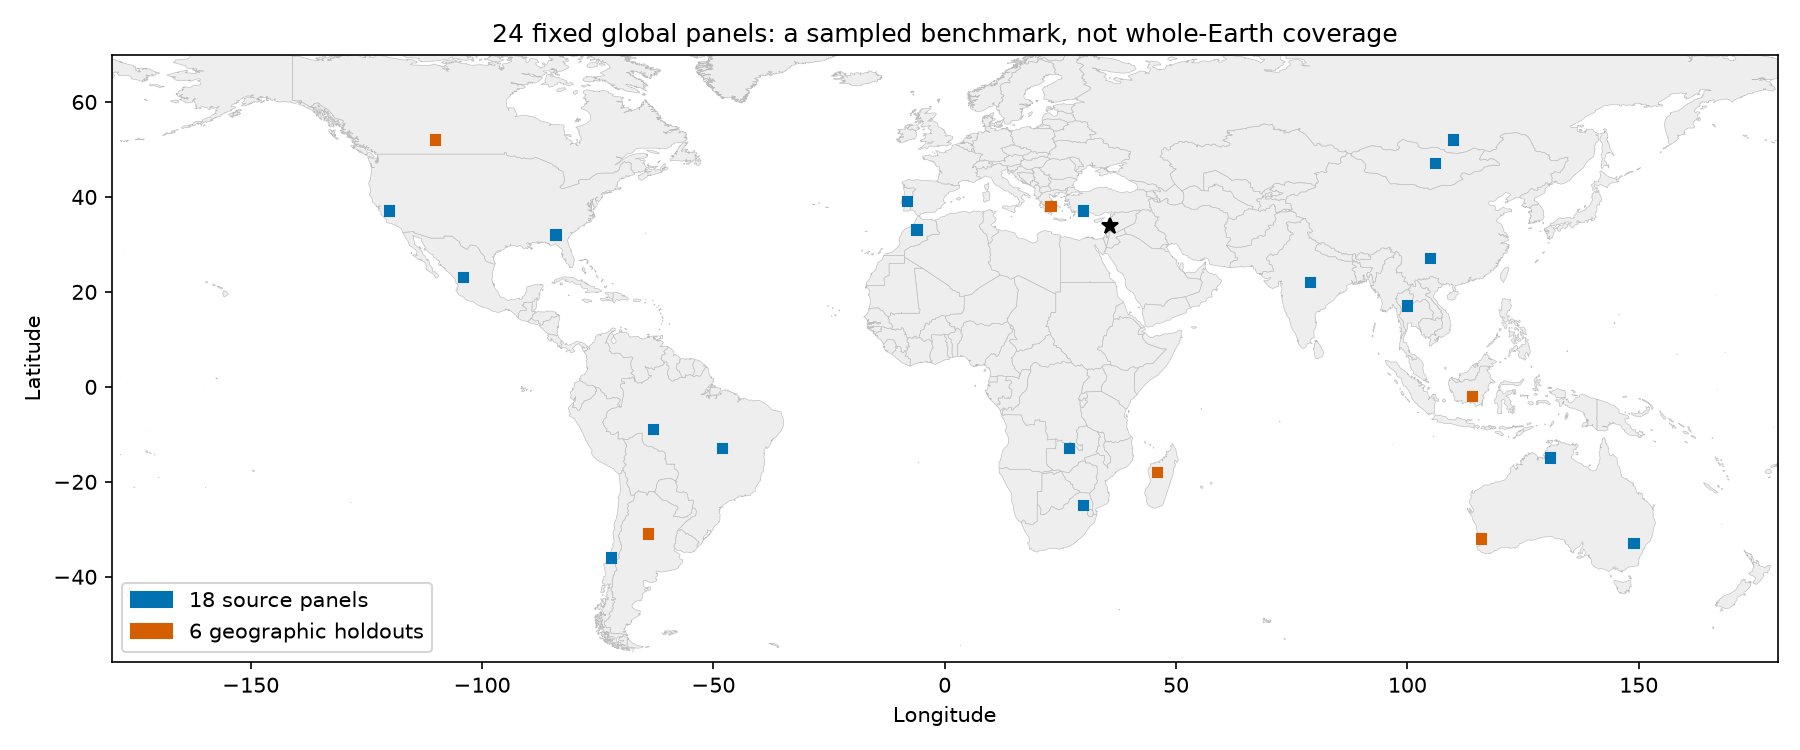

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from firecast.global_acquire import sample_days
from firecast.global_data import count_pixels, FEATURES
from firecast.gridded import label_counts
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
config = json.loads((ROOT / 'configs/global-benchmark.json').read_text())
manifest = json.loads((ROOT / 'outputs/global-transfer-data/dataset-manifest.json').read_text())
archive = json.loads((ROOT / 'data/global-panel/archive-report.json').read_text())
assert archive['complete'] and len(config['sites']) == 24
print('Panels:', len(config['sites']), 'fixed sample dates:', len(sample_days(config)))
print('Source sites:', sum(not s['geographic_holdout'] for s in config['sites']))
display(Image(filename=str(ROOT / 'docs/figures/global-sampling.png')))

## Source-only exploration before 2021
The table uses fitting rows only. It exposes different climates, terrain, vegetation and observed fire prevalence; it does not certify every country as comparable to Lebanon. Source-site names and review flags are not learned features. All qualified sampled windows are retained, including non-fire observations.

In [2]:
from firecast.benchmark_global import load_part
source = load_part(ROOT / 'outputs/global-transfer-data', 'global-train', manifest)
assert source.prediction_time.max() < pd.Timestamp('2021-01-01T00:00:00Z')
display(source.groupby('region', observed=True).agg(windows=('y','size'), positive_windows=('y','sum'), mean_temperature_c=('temperature_c','mean'), mean_daily_rain_mm=('precip_mm','mean'), vegetation_fraction=('vegetation_fraction','mean'), mean_elevation_m=('elevation_m','mean')))
display(source.assign(month=source.prediction_time.dt.month).groupby('month').agg(windows=('y','size'), positive_windows=('y','sum')))
print('Actual model features:', FEATURES)

,windows,positive_windows,mean_temperature_c,mean_daily_rain_mm,vegetation_fraction,mean_elevation_m
region,,,,,,
brazil_amazon,18265,777.0,27.141190,2.534532,0.994320,117.923993
brazil_cerrado,23266,284.0,27.254435,1.323717,0.996508,473.303377
california,25032,131.0,16.718280,0.578417,0.972279,575.301808
central_chile,19885,144.0,14.846494,0.374454,0.961409,467.361787
central_india,22487,209.0,25.347409,1.532544,0.993792,493.638242
mexico,23261,121.0,17.830510,0.905515,0.999531,1995.862118
mongolia,19233,0.0,7.066397,0.888454,0.996303,1382.442758
morocco,25105,4.0,17.993790,1.516574,0.961898,1017.708086
new_south_wales,25334,27.0,16.285495,1.122782,0.998492,552.143865


,windows,positive_windows
month,,
1,27387,166.0
2,29279,236.0
3,33434,419.0
4,34855,389.0
5,36729,415.0
6,36884,540.0
7,35791,821.0
8,35685,1210.0
9,37168,833.0


Actual model features: ['temperature_c', 'humidity_pct', 'precip_mm', 'wind_u_ms', 'wind_v_ms', 'rain7_mm', 'rain30_mm', 'temperature7_c', 'vpd_kpa', 'vegetation_fraction', 'elevation_m', 'slope_deg', 'aspect_sin', 'aspect_cos', 'latitude', 'season_sin', 'season_cos', 'hemisphere_season_sin', 'hemisphere_season_cos']


## Decode real source pixels through the shared adapter
This is a training-era source example, not invented fire evidence. The adapter preserves each confidence/cloud class and land QA. Any fire outside eligibility or with incompatible land QA quarantines its cell-window; insufficient coverage stays uncertain. The inspected historical QA amendment affects only a window already null in the original dataset, so the recorded fitted targets are unchanged.

In [3]:
path = next(p for p in sorted((ROOT / 'data/global-panel/fire').glob('*.npz')) if '.A2018' in p.name)
metadata = json.loads(path.with_suffix('.npz.manifest.json').read_text())
with np.load(path) as raw:
    site = metadata['site_order'][0]
    use = raw['site_id'] == site
    mapping = dict(np.load(ROOT / 'data/global-panel/maps' / (site + '-' + metadata['tile'] + '.npz')))
    counts = count_pixels(raw['FireMask'][use], raw['QA'][use], mapping, site, metadata['date'])
    display(pd.Series(raw['FireMask'][use]).value_counts().sort_index().rename('raw_native_pixels').to_frame())
cells = pd.read_csv(ROOT / 'data/global-panel/static' / (site + '-cells.csv'))
counts = counts.merge(cells[['cell_id','eligible_pixels']], on='cell_id', validate='one_to_one')
counts['processed_fraction'] = counts.processed / counts.eligible_pixels
counts['status'], counts['y'] = label_counts(counts, np.zeros(len(counts), bool), 'strict', .8)
assert counts.loc[counts.status.isin(['excluded','uncertain','positive_low_coverage']), 'y'].isna().all()
display(counts[['cell_id','processed_fraction','fire','noneligible_fire','status','y']].head())
print('Original source URL:', metadata['url'])
print('Original hash:', metadata['original_sha256'], 'retained subset hash:', metadata['subset_sha256'])

,raw_native_pixels
3,475
4,12545
5,32980


,cell_id,processed_fraction,fire,noneligible_fire,status,y
0,1260_590,1.000000,0,0,negative,0.0
1,1260_591,0.974359,0,0,negative,0.0
2,1260_592,1.000000,0,0,negative,0.0
3,1260_593,1.000000,0,0,negative,0.0
4,1260_594,0.913793,0,0,negative,0.0


Original source URL: https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/VJ114A1.002/VJ114A1.A2018029.h08v05.002.2022258034624/VJ114A1.A2018029.h08v05.002.2022258034624.h5
Original hash: 3824ba513d53f531c56129d5746661e7cd2efa434ac858641709f40668672304 retained subset hash: a25bfa99d358d9d5f8aeac885092766eb370ea54c35806150dee7154d892404d


## Independent weather history and label coverage
POWER returns observed/reanalysis-derived meteorology, not archived issued forecasts. Rainfall histories end three days before prediction; rolling features never use the target day. Source cloud/processing fractions belong only to label qualification, not predictors. No complete NDVI history or facility/strike catalogue is invented.

In [4]:
weather_report = json.loads((ROOT / 'data/global-weather/weather-report.json').read_text())
print('Weather points / point-days:', weather_report['points'], weather_report['point_days'])
assert weather_report['missing_requested_values'] == 0
assert not {'processed_fraction','fire','conflict_excluded','y'} & set(FEATURES)
qa = json.loads((ROOT / 'docs/global-qa-audit.json').read_text())
display(pd.DataFrame([{ 'source':name, **{k:v for k,v in value.items() if isinstance(v,(int,float))}} for name,value in qa.items() if isinstance(value,dict)]))

Weather points / point-days: 384 1133952


,source,files_checked,files,fire_pixels,incompatible_land_qa_fire_pixels,affected_cell_windows
0,original_lebanon_archive,5825.0,NaN,NaN,NaN,NaN
1,global_selected_2018_2025,NaN,4608.0,42106.0,2.0,1.0
2,global_selected_2026,NaN,479.0,5233.0,0.0,NaN
3,lebanon_2026,NaN,608.0,145.0,0.0,NaN


## Broad southern-Lebanon conflict quarantine
The policy excludes every cell intersecting South/El Nabatieh plus a 1km buffer from 7 October 2023 onward. It is not proof that a particular fire was caused by conflict. ACLED requires authorized access; no complete strike-to-fire catalogue was acquired, and other regions are not certified conflict-free. The source license is CC BY-IGO. Old labels remain in the audit and excluded targets are null, never zero.

In [5]:
conflict = json.loads((ROOT / 'configs/conflict-review.json').read_text())
print(conflict['governorate_names'], conflict['start'], 'buffer metres:', conflict['boundary_buffer_m'])
print('Boundary source:', conflict['source_url'])
assert len(manifest['conflict_excluded_cell_ids']) == 32
f = pd.read_csv(ROOT / 'outputs/global-transfer-data/lebanon-known-test.csv.gz', usecols=['cell_id','prediction_time','y','y_before_conflict_quarantine','conflict_excluded','exclusion_reason'], low_memory=False)
excluded = f.conflict_excluded
assert f.loc[excluded, 'y'].isna().all()
display(f[excluded & f.y_before_conflict_quarantine.eq(1)].head())
print('Excluded windows:', int(excluded.sum()), 'previously qualified positives excluded:', int((excluded & f.y_before_conflict_quarantine.eq(1)).sum()))

['El Nabatieh', 'South'] 2023-10-07T00:00:00Z buffer metres: 1000
Boundary source: https://data.humdata.org/dataset/cod-ab-lbn


,cell_id,prediction_time,y,conflict_excluded,exclusion_reason,y_before_conflict_quarantine
285,1230_2151,2023-10-20 00:00:00+00:00,NaN,True,User-requested broad conflict-contamination qu...,1.0
286,1230_2151,2023-10-21 00:00:00+00:00,NaN,True,User-requested broad conflict-contamination qu...,1.0
287,1230_2151,2023-10-22 00:00:00+00:00,NaN,True,User-requested broad conflict-contamination qu...,1.0
290,1230_2151,2023-10-25 00:00:00+00:00,NaN,True,User-requested broad conflict-contamination qu...,1.0
492,1230_2151,2024-05-14 00:00:00+00:00,NaN,True,User-requested broad conflict-contamination qu...,1.0


Excluded windows: 25888 previously qualified positives excluded: 143


## Dataset exports and split identities
Separate files contain fitting (2018–2020), calibration (2021), validation (2022), later global temporal/geographic tests, the already-known Lebanese 2023–2025 benchmark and the fixed 2026 Lebanese fold. Seven-day boundary gaps avoid overlapping windows; they do not prove independent incidents. Entire geographic sites are withheld from source fitting/calibration.

In [6]:
display(pd.DataFrame(manifest['global']).T[['rows','first_prediction','last_window_end','qualified_rows','positive_windows']])
display(pd.DataFrame(manifest['lebanon']).T[['rows','conflict_quarantined_windows','first_prediction','last_window_end']])
print('Reusable modules: global_acquire, global_weather, global_data, conflict_review')
print('Statecharts:', ROOT / 'docs/global-statecharts.md')

,rows,first_prediction,last_window_end,qualified_rows,positive_windows
train,502467,2018-01-29 00:00:00+00:00,2020-12-05 00:00:00+00:00,401767,5769
calibration,169848,2021-01-23 00:00:00+00:00,2021-12-11 00:00:00+00:00,136004,1754
validation,162771,2022-01-22 00:00:00+00:00,2022-12-14 00:00:00+00:00,133335,1922
test-sealed,509544,2023-01-14 00:00:00+00:00,2025-12-30 00:00:00+00:00,NaN,NaN
geographic-test-sealed,159120,2023-01-14 00:00:00+00:00,2025-12-30 00:00:00+00:00,NaN,NaN


,rows,conflict_quarantined_windows,first_prediction,last_window_end
train,134912,0,2018-01-01 00:00:00+00:00,2020-12-24 00:00:00+00:00
calibration,43400,0,2021-01-08 00:00:00+00:00,2021-12-24 00:00:00+00:00
validation,43400,0,2022-01-08 00:00:00+00:00,2022-12-24 00:00:00+00:00
known-test,134044,25888,2023-01-08 00:00:00+00:00,2025-12-24 00:00:00+00:00
confirmation-sealed,36828,9504,2026-01-08 00:00:00+00:00,2026-11-01 00:00:00+00:00


Reusable modules: global_acquire, global_weather, global_data, conflict_review
Statecharts: /workspace/work/nasa-harmonization/forecasting/docs/global-statecharts.md
